<a href="https://colab.research.google.com/github/Zwelakhe-git/zvelake_githubio/blob/main/lab3_rock_music_rnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа 3: генерация рок-музыки с помощью RNN

Основа — туториал TensorFlow [Generate music with an RNN](https://www.tensorflow.org/tutorials/audio/music_generation).
Отличия от туториала:
- вместо классического датасета MAESTRO (фортепиано) используется рок-подборка из Lakh MIDI Dataset (`clean_midi`);
- из каждого MIDI-файла берётся гитарная дорожка (барабаны пропускаются);
- сгенерированная мелодия озвучивается инструментом *Distortion Guitar*;
- исправлена совместимость с NumPy 2 / Keras 3 и нормализация pitch при генерации.

## Установка библиотек

In [ ]:
!sudo apt install -y fluidsynth
!pip install --upgrade pyfluidsynth
!pip install pretty_midi

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  at-spi2-common at-spi2-core fluid-soundfont-gm gsettings-desktop-schemas
  libatk-bridge2.0-0t64 libatk1.0-0t64 libatspi2.0-0t64 libb2-1
  libdouble-conversion3 libevdev2 libfluidsynth3 libgtk-3-0t64 libgtk-3-bin
  libgtk-3-common libgudev-1.0-0 libinput-bin libinput10 libinstpatch-1.0-2
  libmd4c0 libmtdev1t64 libpipewire-0.3-0t64 libpipewire-0.3-common
  libproxy1v5 libqt6core6t64 libqt6dbus6t64 libqt6gui6t64 libqt6network6t64
  libqt6opengl6t64 libqt6qml6 libqt6qmlmodels6 libqt6quick6
  libqt6waylandclient6 libqt6waylandcompositor6
  libqt6waylandeglclienthwintegration6
  libqt6waylandeglcompositorhwintegration6 libqt6widgets6t64
  libqt6wlshellintegration6 librsvg2-common libspa-0.2-modules libts0t64
  libwacom-common libwacom9 libwayland-server0 libwebrtc-audio-processing1
  libxcb-icccm4 libxcb-image0 libxcb-keysyms1 libxcb-render

## Импорты

In [ ]:
import collections
import glob
import os
import random
import warnings

import fluidsynth
import numpy as np
import pandas as pd
import pretty_midi
import seaborn as sns
import tensorflow as tf

from IPython import display
from matplotlib import pyplot as plt
from typing import Optional

warnings.filterwarnings('ignore')  # pretty_midi часто предупреждает о tempo/meta-событиях

seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)
random.seed(seed)

# Частота дискретизации для прослушивания
_SAMPLING_RATE = 16000

## Загрузка рок-датасета

`clean_midi` из Lakh MIDI Dataset — около 17 тыс. MIDI-файлов, разложенных по папкам исполнителей.
Отбираем файлы рок-групп по имени папки.

In [ ]:
if not os.path.exists('clean_midi'):
  !wget -q http://hog.ee.columbia.edu/craffel/lmd/clean_midi.tar.gz
  !tar -xzf clean_midi.tar.gz

In [ ]:
rock_artists = {a.lower() for a in [
    'Queen', 'Led Zeppelin', 'Deep Purple', 'Nirvana', 'Metallica',
    'Black Sabbath', 'Aerosmith', 'Bon Jovi', 'Scorpions', 'Pink Floyd',
    'The Rolling Stones', 'Kiss', 'Iron Maiden', "Guns N' Roses",
    'Van Halen', 'Def Leppard', 'Eagles', 'The Who', 'Rainbow']}

all_files = glob.glob('clean_midi/**/*.mid*', recursive=True)
filenames = [f for f in all_files
             if os.path.basename(os.path.dirname(f)).lower() in rock_artists]
random.shuffle(filenames)  # чтобы в обучение попали разные группы

print('Всего файлов:', len(all_files), '| рок:', len(filenames))
found = sorted({os.path.basename(os.path.dirname(f)) for f in filenames})
print('Найденные исполнители:', found)
if not filenames:
  print('Рок-файлы не найдены. Пример путей в архиве:', all_files[:5])

Всего файлов: 17243 | рок: 1357
Найденные исполнители: ['Aerosmith', 'Black Sabbath', 'Bon Jovi', 'Deep Purple', 'Def Leppard', 'Eagles', "Guns N' Roses", 'Iron Maiden', 'Kiss', 'Led Zeppelin', 'Metallica', 'Nirvana', 'Pink Floyd', 'Queen', 'Rainbow', 'Scorpions', 'The Rolling Stones', 'The Who', 'Van Halen']


## Обработка MIDI-файла

В рок-песнях несколько инструментов, и `instruments[0]` часто оказывается барабанами или вокалом.
Поэтому выбираем гитару (программы MIDI 24–31), а если её нет — самую длинную не-барабанную дорожку.

In [ ]:
def pick_instrument(pm: pretty_midi.PrettyMIDI) -> Optional[pretty_midi.Instrument]:
  melodic = [i for i in pm.instruments if not i.is_drum and len(i.notes) > 50]
  if not melodic:
    return None
  guitars = [i for i in melodic if 24 <= i.program <= 31]
  return max(guitars or melodic, key=lambda i: len(i.notes))


def midi_to_notes(midi_file: str) -> Optional[pd.DataFrame]:
  pm = pretty_midi.PrettyMIDI(midi_file)
  instrument = pick_instrument(pm)
  if instrument is None:
    return None
  notes = collections.defaultdict(list)

  # Сортируем ноты по времени начала
  sorted_notes = sorted(instrument.notes, key=lambda note: note.start)
  prev_start = sorted_notes[0].start

  for note in sorted_notes:
    start = note.start
    end = note.end
    notes['pitch'].append(note.pitch)
    notes['start'].append(start)
    notes['end'].append(end)
    notes['step'].append(start - prev_start)
    notes['duration'].append(end - start)
    prev_start = start

  return pd.DataFrame({name: np.array(value) for name, value in notes.items()})


def display_audio(pm: pretty_midi.PrettyMIDI, seconds=30):
  waveform = pm.fluidsynth(fs=_SAMPLING_RATE)
  # Берём только начало, чтобы не перегружать ядро
  waveform_short = waveform[:seconds*_SAMPLING_RATE]
  return display.Audio(waveform_short, rate=_SAMPLING_RATE)

Посмотрим на один файл: какие в нём инструменты и какую дорожку мы выбрали.

In [ ]:
# Берём первый файл, у которого нашлась подходящая дорожка
for sample_file in filenames:
  try:
    sample_pm = pretty_midi.PrettyMIDI(sample_file)
    if pick_instrument(sample_pm) is not None:
      break
  except Exception:
    pass

print(sample_file)
for inst in sample_pm.instruments:
  name = 'Drums' if inst.is_drum else pretty_midi.program_to_instrument_name(inst.program)
  print(f'  {name:30s} нот: {len(inst.notes)}')

chosen = pick_instrument(sample_pm)
print('Выбрана дорожка:', pretty_midi.program_to_instrument_name(chosen.program))
display_audio(sample_pm)

clean_midi/Metallica/Blitzkrieg.2.mid
  Electric Guitar (clean)        нот: 996
  Church Organ                   нот: 996
  Contrabass                     нот: 219
  Synth Brass 1                  нот: 355
  Lead 8 (bass + lead)           нот: 38
  Distortion Guitar              нот: 373
  Harpsichord                    нот: 902
  Lead 1 (square)                нот: 902
  Electric Guitar (muted)        нот: 902
  Drums                          нот: 35
  Drums                          нот: 320
  Drums                          нот: 309
  Drums                          нот: 26
Выбрана дорожка: Electric Guitar (clean)


In [ ]:
raw_notes = midi_to_notes(sample_file)
raw_notes.head()

,pitch,start,end,step,duration
0,55,1.441667,1.758333,0.000000,0.316667
1,62,1.758333,1.920000,0.316667,0.161667
2,64,1.918333,2.076667,0.160000,0.158333
3,52,2.078333,2.236667,0.160000,0.158333
4,52,2.238333,2.400000,0.160000,0.161667


In [ ]:
def plot_piano_roll(notes: pd.DataFrame, count: Optional[int] = None):
  if count:
    title = f'First {count} notes'
  else:
    title = f'Whole track'
    count = len(notes['pitch'])
  plt.figure(figsize=(20, 4))
  plot_pitch = np.stack([notes['pitch'], notes['pitch']], axis=0)
  plot_start_stop = np.stack([notes['start'], notes['end']], axis=0)
  plt.plot(
      plot_start_stop[:, :count], plot_pitch[:, :count], color="b", marker=".")
  plt.xlabel('Time [s]')
  plt.ylabel('Pitch')
  _ = plt.title(title)


def plot_distributions(notes: pd.DataFrame, drop_percentile=2.5):
  plt.figure(figsize=[15, 5])
  plt.subplot(1, 3, 1)
  sns.histplot(notes, x="pitch", bins=20)

  plt.subplot(1, 3, 2)
  max_step = np.percentile(notes['step'], 100 - drop_percentile)
  sns.histplot(notes, x="step", bins=np.linspace(0, max_step, 21))

  plt.subplot(1, 3, 3)
  max_duration = np.percentile(notes['duration'], 100 - drop_percentile)
  sns.histplot(notes, x="duration", bins=np.linspace(0, max_duration, 21))

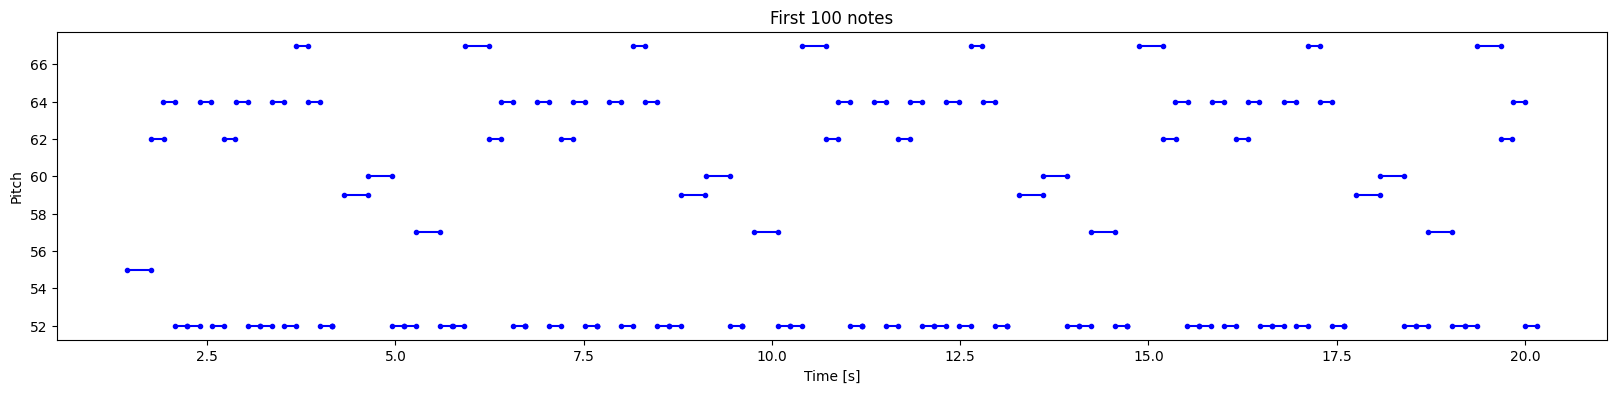

In [ ]:
plot_piano_roll(raw_notes, count=100)

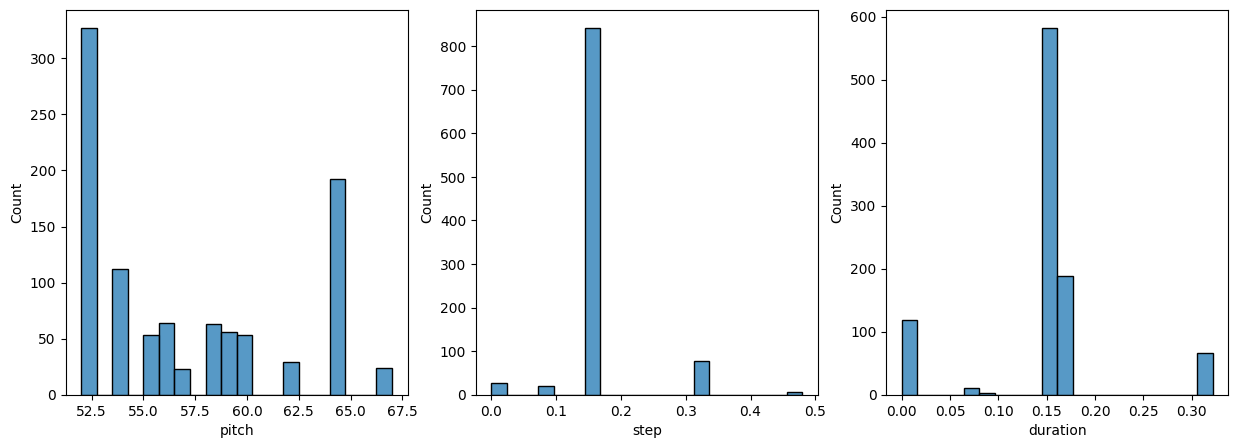

In [ ]:
plot_distributions(raw_notes)

## Преобразование нот обратно в MIDI

In [ ]:
def notes_to_midi(
  notes: pd.DataFrame,
  out_file: str,
  instrument_name: str,
  velocity: int = 100,  # громкость ноты
) -> pretty_midi.PrettyMIDI:

  pm = pretty_midi.PrettyMIDI()
  instrument = pretty_midi.Instrument(
      program=pretty_midi.instrument_name_to_program(instrument_name))

  prev_start = 0
  for i, note in notes.iterrows():
    start = float(prev_start + note['step'])
    end = float(start + note['duration'])
    note = pretty_midi.Note(
        velocity=velocity,
        pitch=int(note['pitch']),
        start=start,
        end=end,
    )
    instrument.notes.append(note)
    prev_start = start

  pm.instruments.append(instrument)
  pm.write(out_file)
  return pm

## Создание обучающего датасета

Часть файлов в Lakh повреждена, поэтому загрузку оборачиваем в `try`.

In [ ]:
num_files = 40
all_notes = []
for f in filenames:
  if len(all_notes) >= num_files:
    break
  try:
    n = midi_to_notes(f)
    if n is not None:
      all_notes.append(n)
  except Exception as e:
    print('пропуск', os.path.basename(f), '-', e)

print('Использовано файлов:', len(all_notes))
all_notes = pd.concat(all_notes)
n_notes = len(all_notes)
print('Всего нот:', n_notes)

Использовано файлов: 40
Всего нот: 49319


In [ ]:
key_order = ['pitch', 'step', 'duration']
train_notes = np.stack([all_notes[key] for key in key_order], axis=1)
notes_ds = tf.data.Dataset.from_tensor_slices(train_notes)
notes_ds.element_spec

TensorSpec(shape=(3,), dtype=tf.float64, name=None)

In [ ]:
def create_sequences(
    dataset: tf.data.Dataset,
    seq_length: int,
    vocab_size = 128,
) -> tf.data.Dataset:
  """Возвращает датасет пар (последовательность, следующая нота)."""
  seq_length = seq_length+1

  # Берём на 1 больше — последняя нота будет меткой
  windows = dataset.window(seq_length, shift=1, stride=1,
                              drop_remainder=True)

  flatten = lambda x: x.batch(seq_length, drop_remainder=True)
  sequences = windows.flat_map(flatten)

  # Нормализация pitch
  def scale_pitch(x):
    x = x/[vocab_size,1.0,1.0]
    return x

  # Разделяем входы и метки
  def split_labels(sequences):
    inputs = sequences[:-1]
    labels_dense = sequences[-1]
    labels = {key:labels_dense[i] for i,key in enumerate(key_order)}
    return scale_pitch(inputs), labels

  return sequences.map(split_labels, num_parallel_calls=tf.data.AUTOTUNE)

In [ ]:
seq_length = 25
vocab_size = 128
seq_ds = create_sequences(notes_ds, seq_length, vocab_size)
seq_ds.element_spec

(TensorSpec(shape=(25, 3), dtype=tf.float64, name=None),
 {'pitch': TensorSpec(shape=(), dtype=tf.float64, name=None),
  'step': TensorSpec(shape=(), dtype=tf.float64, name=None),
  'duration': TensorSpec(shape=(), dtype=tf.float64, name=None)})

In [ ]:
batch_size = 64
buffer_size = n_notes - seq_length
train_ds = (seq_ds
            .shuffle(buffer_size)
            .batch(batch_size, drop_remainder=True)
            .cache()
            .prefetch(tf.data.experimental.AUTOTUNE))
train_ds.element_spec

(TensorSpec(shape=(64, 25, 3), dtype=tf.float64, name=None),
 {'pitch': TensorSpec(shape=(64,), dtype=tf.float64, name=None),
  'step': TensorSpec(shape=(64,), dtype=tf.float64, name=None),
  'duration': TensorSpec(shape=(64,), dtype=tf.float64, name=None)})

## Создание и обучение модели

In [ ]:
def mse_with_positive_pressure(y_true: tf.Tensor, y_pred: tf.Tensor):
  mse = (y_true - y_pred) ** 2
  positive_pressure = 10 * tf.maximum(-y_pred, 0.0)
  return tf.reduce_mean(mse + positive_pressure)

In [ ]:
input_shape = (seq_length, 3)
learning_rate = 0.005

inputs = tf.keras.Input(input_shape)
x = tf.keras.layers.LSTM(128)(inputs)

outputs = {
  'pitch': tf.keras.layers.Dense(128, name='pitch')(x),
  'step': tf.keras.layers.Dense(1, name='step')(x),
  'duration': tf.keras.layers.Dense(1, name='duration')(x),
}

model = tf.keras.Model(inputs, outputs)

loss = {
      'pitch': tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
      'step': mse_with_positive_pressure,
      'duration': mse_with_positive_pressure,
}

optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)

model.compile(
    loss=loss,
    loss_weights={'pitch': 0.05, 'step': 1.0, 'duration': 1.0},
    optimizer=optimizer,
)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 25, 3)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 128)       │     67,584 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ duration (Dense)    │ (None, 1)         │        129 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pitch (Dense)       │ (None, 128)       │     16,512 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ step (Dense)        │ (None, 1)         │        129 │ lstm[0][0]        │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 84,354 (329.51 KB)

 Trainable params: 84,354 (329.51 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath='./training_checkpoints/ckpt_{epoch}.weights.h5',
        save_weights_only=True),
    tf.keras.callbacks.EarlyStopping(
        monitor='loss',
        patience=5,
        verbose=1,
        restore_best_weights=True),
]

In [ ]:
%%time
epochs = 50

history = model.fit(
    train_ds,
    epochs=epochs,
    callbacks=callbacks,
)

Epoch 1/50
770/770 ━━━━━━━━━━━━━━━━━━━━ 17s 7ms/step - duration_loss: 0.1000 - loss: 1.6592 - pitch_loss: 3.5509 - step_loss: 1.3817
Epoch 2/50
770/770 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - duration_loss: 0.0935 - loss: 1.6292 - pitch_loss: 3.3647 - step_loss: 1.3675
Epoch 3/50
770/770 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - duration_loss: 0.0905 - loss: 1.6127 - pitch_loss: 3.2614 - step_loss: 1.3592
Epoch 4/50
770/770 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - duration_loss: 0.0886 - loss: 1.6008 - pitch_loss: 3.1106 - step_loss: 1.3566
Epoch 5/50
770/770 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - duration_loss: 0.0871 - loss: 1.5847 - pitch_loss: 3.0317 - step_loss: 1.3461
Epoch 6/50
770/770 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - duration_loss: 0.0859 - loss: 1.5776 - pitch_loss: 2.9747 - step_loss: 1.3430
Epoch 7/50
770/770 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - duration_loss: 0.0864 - loss: 1.5764 - pitch_loss: 3.0313 - step_loss: 1.3385
Epoch 8/50
770/770 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - duration_loss: 0.0840

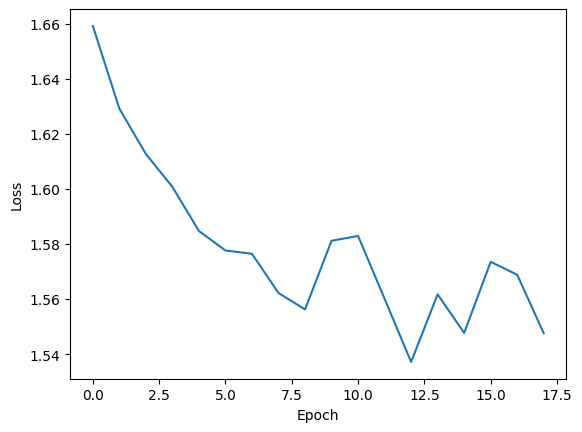

In [ ]:
plt.plot(history.epoch, history.history['loss'], label='total loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

## Генерация нот

In [ ]:
def predict_next_note(
    notes: np.ndarray,
    model: tf.keras.Model,
    temperature: float = 1.0) -> tuple[int, float, float]:
  """Предсказывает следующую ноту (pitch, step, duration)."""

  assert temperature > 0

  # Добавляем размерность батча
  inputs = tf.expand_dims(notes, 0)

  predictions = model.predict(inputs, verbose=0)
  pitch_logits = predictions['pitch']
  step = predictions['step']
  duration = predictions['duration']

  pitch_logits /= temperature
  pitch = tf.random.categorical(pitch_logits, num_samples=1)
  pitch = tf.squeeze(pitch, axis=-1)
  duration = tf.squeeze(duration, axis=-1)
  step = tf.squeeze(step, axis=-1)

  # step и duration не могут быть отрицательными
  step = tf.maximum(0, step)
  duration = tf.maximum(0, duration)

  # [0] — исправление для NumPy 2: после squeeze форма (1,), а не скаляр
  return int(pitch[0]), float(step[0]), float(duration[0])

In [ ]:
temperature = 2.0
num_predictions = 120

# Стартовая последовательность — из рок-песни
sample_notes = np.stack([raw_notes[key] for key in key_order], axis=1)

# pitch нормализуется так же, как при обучении
input_notes = (
    sample_notes[:seq_length] / np.array([vocab_size, 1, 1]))

generated_notes = []
prev_start = 0
for _ in range(num_predictions):
  pitch, step, duration = predict_next_note(input_notes, model, temperature)
  start = prev_start + step
  end = start + duration
  input_note = (pitch, step, duration)
  generated_notes.append((*input_note, start, end))
  input_notes = np.delete(input_notes, 0, axis=0)
  # новую ноту тоже нормализуем
  input_notes = np.append(
      input_notes, [[pitch / vocab_size, step, duration]], axis=0)
  prev_start = start

generated_notes = pd.DataFrame(
    generated_notes, columns=(*key_order, 'start', 'end'))
generated_notes.head(10)

,pitch,step,duration,start,end
0,47,0.268879,0.286029,0.268879,0.554909
1,55,0.242175,0.285650,0.511054,0.796704
2,64,0.255633,0.290416,0.766687,1.057103
3,47,0.222141,0.320835,0.988829,1.309663
4,60,0.276255,0.329820,1.265084,1.594904
5,76,0.254579,0.326434,1.519663,1.846097
6,50,0.232228,0.372647,1.751891,2.124537
7,66,0.285110,0.392959,2.037000,2.429959
8,84,0.272791,0.391425,2.309791,2.701216
9,52,0.246146,0.445603,2.555937,3.001541


In [ ]:
instrument_name = 'Distortion Guitar'   # можно 'Overdriven Guitar'
out_file = 'rock_output.mid'
out_pm = notes_to_midi(
    generated_notes, out_file=out_file, instrument_name=instrument_name)
display_audio(out_pm)

Скачать MIDI-файл:

In [ ]:
from google.colab import files
files.download(out_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Анализ сгенерированной музыки

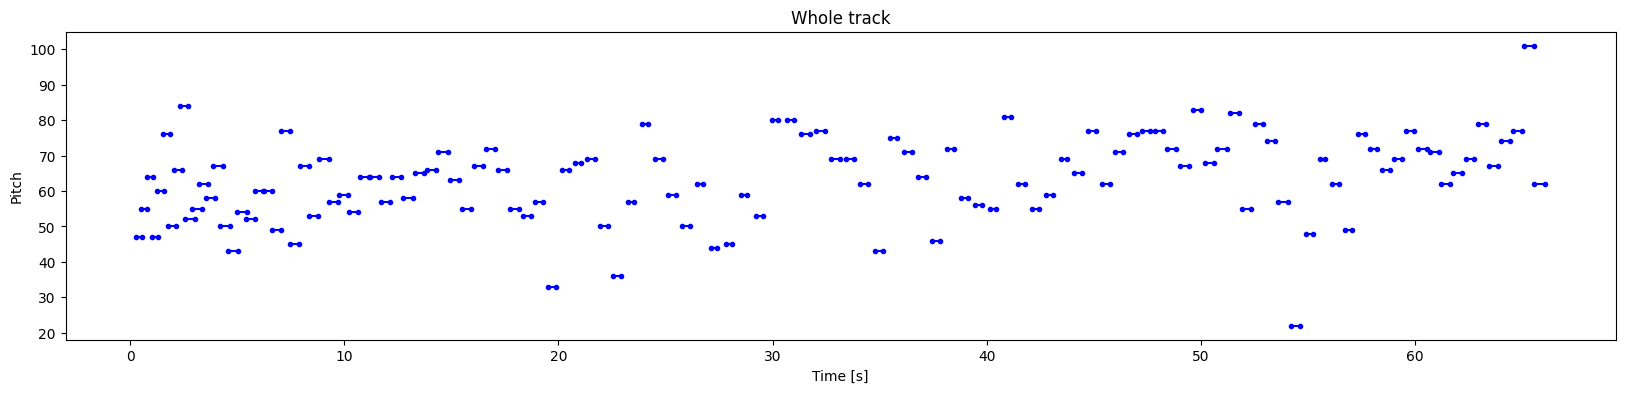

In [ ]:
plot_piano_roll(generated_notes)

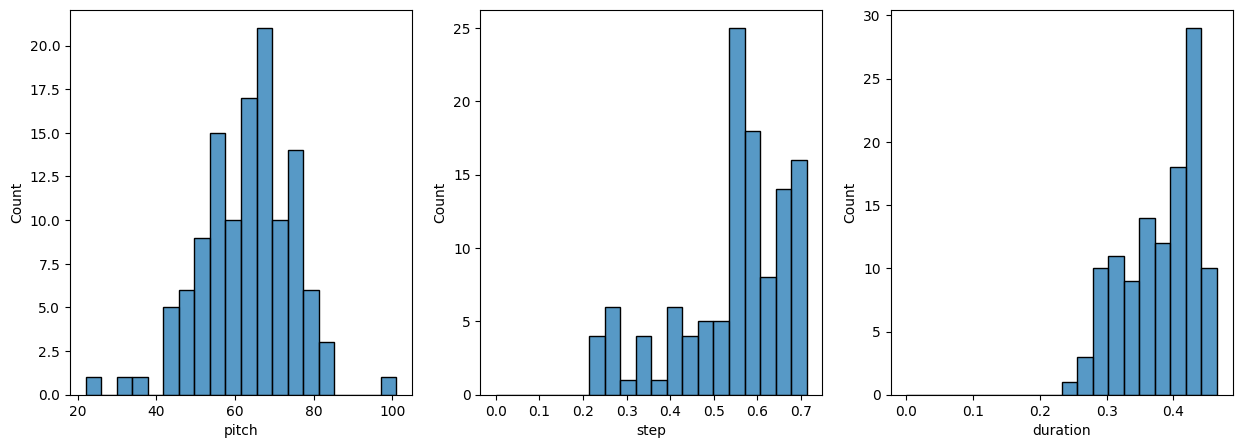

In [ ]:
plot_distributions(generated_notes)